In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
from scipy.stats import gmean
import matplotlib.pyplot as plt 
from mosqlient.scoring import compute_wis, compute_interval_score
import sys
sys.path.append('../')
from aux_func import get_data, code_to_state 

import matplotlib as mpl

# Definir a cor das bordas (spines) como cinza
mpl.rcParams['axes.edgecolor'] = 'gray'

# Definir a cor das linhas dos ticks maiores e menores como cinza
mpl.rcParams['xtick.color'] = 'gray'
mpl.rcParams['ytick.color'] = 'gray'
mpl.rcParams['xtick.labelcolor'] = 'black'
mpl.rcParams['ytick.labelcolor'] = 'black'
plt.rcParams['axes.labelsize'] = 16 # Axis labels
plt.rcParams['xtick.labelsize'] = 14  # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 14  # Y-axis tick labels
plt.rcParams['font.size'] = 16  # General font size
FONT = 12

In [2]:
challenge = 'chik_state'

Load data: 

In [3]:
df_dengue_state = get_data(challenge)
df_dengue_state.date = pd.to_datetime(df_dengue_state.date)
df_dengue_state.head()

,date,adm_1,casos
0,2013-12-29,11,0
1,2013-12-29,12,0
2,2013-12-29,13,0
3,2013-12-29,14,0
4,2013-12-29,15,0


Load ranking: 

In [4]:
remove_models = ['3rd_imdc_-unifesp-_-4mosqueteiras-',
                                      '3rd_imdc_fiocruz_zerolags',
                                        '3rd_imdc_rki_rki_zki_ph',
                               '3rd_imdc_rki_rki_zki_ph_lstm_geo',
                                         '3rd_imdc_unesp_recogna',
 '3rd_imdc_universidad_del_valle_grupo_modelamiento_datos_dengue']

In [5]:
df_rank = pd.read_csv(f'../predictions/rank_ratio_{challenge}.csv')

model_baseline = '3rd_imdc_procc_bb_model'

df_wis_base = df_rank.loc[df_rank.model == model_baseline]

df_rank = df_rank.loc[df_rank.model != model_baseline]

df_rank = df_rank.loc[~df_rank.model.isin(remove_models)]

df_rank = df_rank.loc[df_rank.adm_1 != 32]

df_rank.head()

,model,adm_1,validation,wis,wis_baseline,wis_ratio,region
0,3rd_imdc_emap_epidematicos_prophet_fixed,11,1,1.61,1.225200,1.314071,North
1,3rd_imdc_emap_epidematicos_prophet_fixed,11,2,2.55,1.865080,1.367233,North
2,3rd_imdc_emap_epidematicos_prophet_fixed,11,3,71.58,80.320000,0.891185,North
3,3rd_imdc_emap_epidematicos_prophet_fixed,11,4,11.59,10.390000,1.115496,North
4,3rd_imdc_emap_epidematicos_prophet_fixed,12,1,0.82,1.159976,0.706911,North


In [6]:
df_rank.model.unique()

<ArrowStringArray>
['3rd_imdc_emap_epidematicos_prophet_fixed',
 '3rd_imdc_emap_epidematicos_sarimax_fixed',
                       '3rd_imdc_emap_lstm',
                  '3rd_imdc_emap_xgbsillas',
          '3rd_imdc_lncc_ARp26_chikungunya',
      '3rd_imdc_lncc_clidengo26chikungunya',
  '3rd_imdc_lncc_surge_model26_chikungunya',
                    '3rd_imdc_nus_nus-cerm',
              '3rd_imdc_purdue_neuralearth',
                          'DS-OKSTATE-2026',
                 'mosqlimate-ai-competitor']
Length: 11, dtype: str

Load predictions: 

In [7]:
df_preds = pd.read_csv(f'../predictions/predictions_all_models_{challenge}.csv.gz', index_col = 'Unnamed: 0')
df_preds.date = pd.to_datetime(df_preds.date)
df_preds = df_preds.loc[~df_preds.model.isin(remove_models)]
df_preds = df_preds.loc[df_preds.model != model_baseline]


df_preds = df_preds.loc[df_preds.adm_1 != 32]

df_preds.head()

,date,lower_95,lower_90,lower_80,lower_50,pred,upper_50,upper_80,upper_90,upper_95,adm_1,id,validation,wis,model
0,2022-10-09,2.743512,3.561896,5.283421,9.016248,17.670073,40.444549,89.679029,143.716210,206.231430,33,5354,1,82.77,3rd_imdc_emap_lstm
1,2022-10-16,3.743952,5.428969,6.920945,12.201003,27.237822,55.050853,112.596736,216.009888,325.011995,33,5354,1,82.77,3rd_imdc_emap_lstm
2,2022-10-23,4.875423,5.693745,8.176445,12.618417,22.377075,42.060248,77.746351,114.612724,173.066908,33,5354,1,82.77,3rd_imdc_emap_lstm
3,2022-10-30,3.250737,4.192324,5.602107,9.793079,17.521617,34.101676,68.882955,117.519627,166.359700,33,5354,1,82.77,3rd_imdc_emap_lstm
4,2022-11-06,2.961620,3.732665,5.172567,9.438648,20.027886,46.905846,103.815092,215.222367,336.458355,33,5354,1,82.77,3rd_imdc_emap_lstm


In [8]:
df_preds.model.unique().shape[0]

11

Bora fazer o item 1 usando o wis_ratio

In [9]:
cols_pred = [
    'lower_95', 'lower_90', 'lower_80', 'lower_50', 'pred',
    'upper_50', 'upper_80', 'upper_90', 'upper_95'
]

In [10]:

resultados = []

# Combinações de adm_1 e validation existentes em df_preds
# considerando apenas validation > 2
combinacoes = (
    df_preds.loc[df_preds.validation >= 2, ['adm_1', 'validation']]
    .drop_duplicates()
    .sort_values(['adm_1', 'validation'])
)

for K in np.arange(1, df_preds.model.unique().shape[0]+1): 

    for adm_1, validation in combinacoes.itertuples(index=False):

        # =====================================================
        # Previsões da UF e validation atuais
        # =====================================================
        df_p_ = df_preds.loc[
            (df_preds.adm_1 == adm_1) &
            (df_preds.validation == validation)
        ]

        # =====================================================
        # Ensemble com todos os modelos
        # =====================================================

        # =====================================================
        # Top K modelos definidos pela validation anterior
        # =====================================================

        df_rank_ = df_rank.loc[(df_rank.validation < validation) & (df_rank.adm_1 == adm_1) ].groupby(["adm_1", 
                                                                                                       "model"], as_index=False).agg(
                                        geometric_mean_ratio=("wis_ratio", lambda x: np.exp(np.mean(np.log(x)))),
                                    ).sort_values(["adm_1", "geometric_mean_ratio"])


        top_K_models = (
            df_rank_.sort_values('geometric_mean_ratio')
            ['model']
            .values[:K]
        )

        df_top = (
            df_p_.loc[df_p_.model.isin(top_K_models)]
            .groupby(['date', 'adm_1', 'validation'])[cols_pred]
            .median()
            .reset_index()
        )

        df_top = (
            df_top
            .merge(
                df_dengue_state,
                on=['date', 'adm_1']
            )
            .sort_values('date')
        )

        wis_top_mean = np.mean(
            compute_wis(
                df=df_top[['date'] + cols_pred],
                observed_value=df_top['casos']
            )
        )

        #wis_top_max = np.max(
        #    compute_wis(
        ##        df=df_top[['date'] + cols_pred],
        #        observed_value=df_top['casos']
        #    )
        #)

        #ens_peak = df_top.pred.max()

        #ens_sum = df_top.pred.sum()


        # =====================================================
        # Melhor modelo observado na validation atual
        # =====================================================
        wis_base = (
            df_wis_base.loc[
                (df_wis_base.adm_1 == adm_1) &
                (df_wis_base.validation == validation),
                'wis'
            ]
            .min()
        )

        # =====================================================
        # Salvar resultado
        # =====================================================
        resultados.append({
            'adm_1': adm_1,
            'validation': validation,
            'K': K,
            'wis_top_mean': wis_top_mean,
            #'wis_top_max': wis_top_max,
            #'ens_peak': ens_peak, 
            #'ens_sum': ens_sum, 
            'wis_base': wis_base
        })


df_wis1 = pd.DataFrame(resultados)

df_wis1['wis_ratio'] = df_wis1['wis_top_mean']/df_wis1['wis_base']
df_wis1

,adm_1,validation,K,wis_top_mean,wis_base,wis_ratio
0,11,2,1,2.836761,1.865080,1.520986
1,11,3,1,86.133851,80.320000,1.072384
2,11,4,1,14.577842,10.390000,1.403065
3,12,2,1,4.097970,2.002743,2.046179
4,12,3,1,1.447056,1.470000,0.984392
...,...,...,...,...,...,...
853,52,3,11,19.446453,13.500000,1.440478
854,52,4,11,100.346406,189.570000,0.529337
855,53,2,11,2.596037,2.978542,0.871580
856,53,3,11,1.645989,1.910000,0.861774


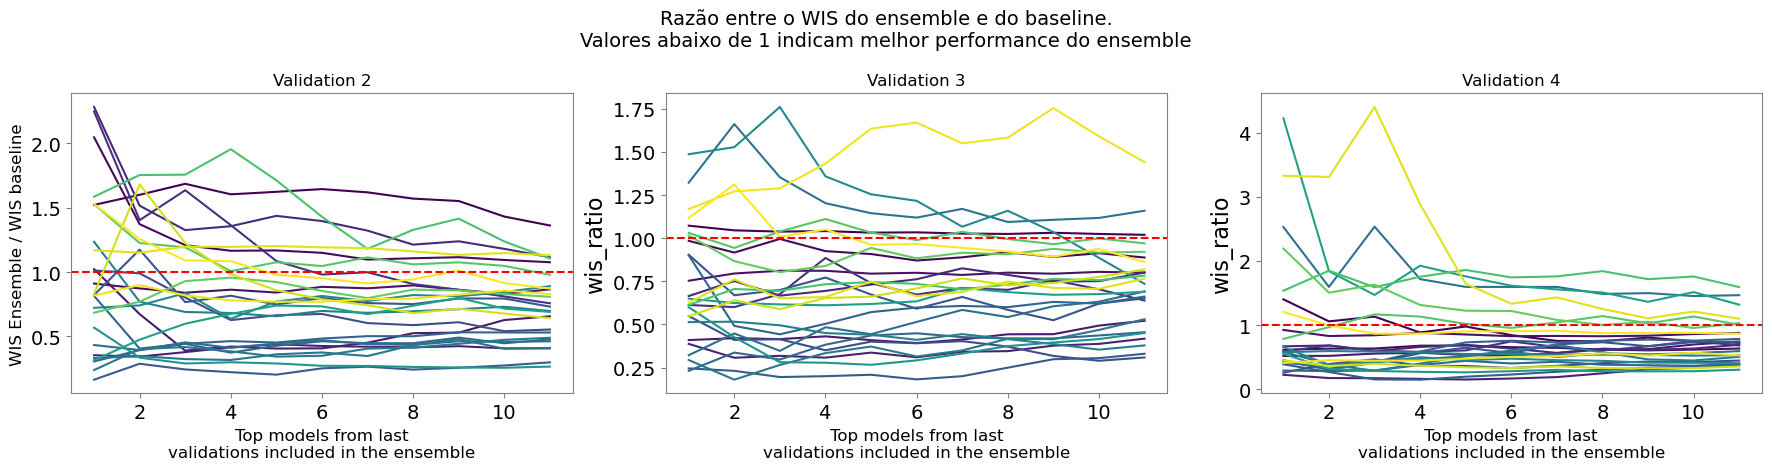

In [11]:
_,ax = plt.subplots(1,3, figsize = (18,5))

for ax_, val in zip(ax.ravel(), [2,3,4]): 

    sns.lineplot(data = df_wis1.loc[df_wis1.validation == val], x = 'K', y = 'wis_ratio', hue = 'adm_1', ax= ax_, palette = 'viridis', legend = False)

    ax_.set_xlabel('Top models from last\nvalidations included in the ensemble', fontsize = 12)

    ax_.set_title(f'Validation {val}', fontsize = 12)

    ax_.axhline(1, color = 'red', linestyle = '--')


ax[0].set_ylabel('WIS Ensemble / WIS baseline',fontsize = 12)

plt.suptitle('Razão entre o WIS do ensemble e do baseline.\nValores abaixo de 1 indicam melhor performance do ensemble',fontsize = 14, y = 0.95)

plt.tight_layout()
plt.show()

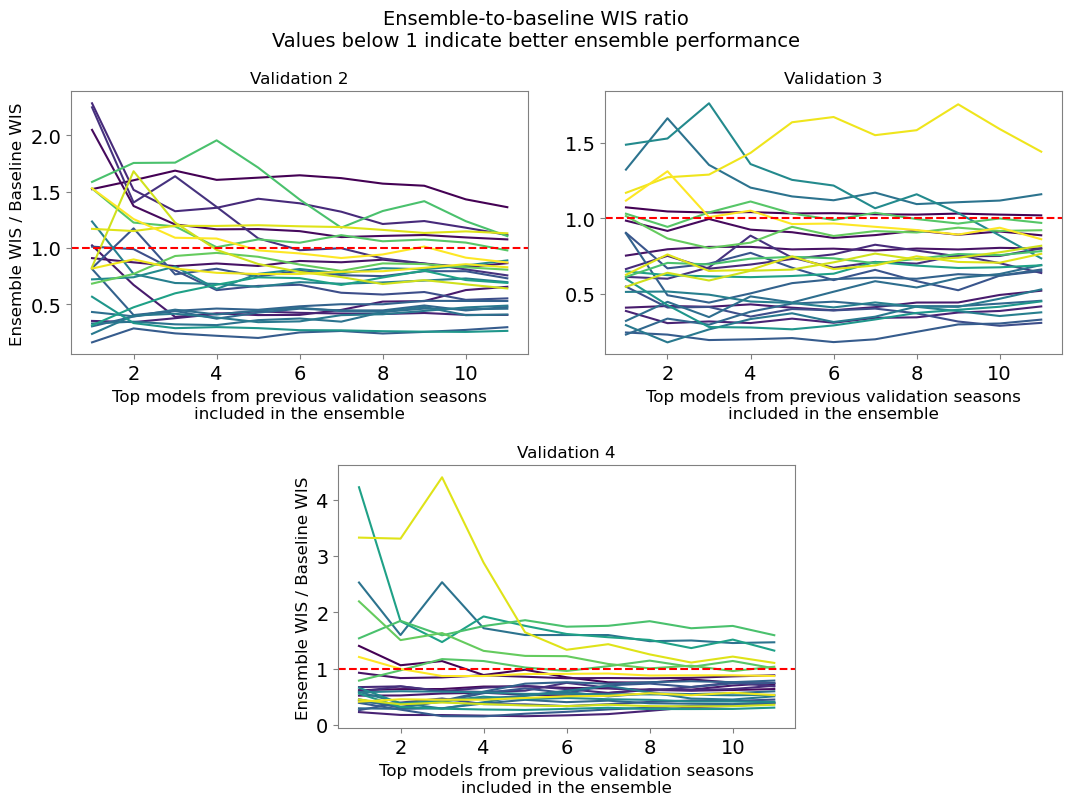

In [12]:
fig = plt.figure(figsize=(11, 9))
gs = fig.add_gridspec(2, 4)

axes = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[1, 1:3]),
]

for ax_, val in zip(axes, [2, 3, 4]):

    sns.lineplot(
        data=df_wis1.loc[df_wis1.validation == val],
        x='K',
        y='wis_ratio',
        hue='adm_1',
        ax=ax_,
        palette='viridis',
        legend=False,
    )

    ax_.set_xlabel(
        'Top models from previous validation seasons\nincluded in the ensemble',
        fontsize=12,
    )

    ax_.set_title(f'Validation {val}', fontsize=12)
    ax_.axhline(1, color='red', linestyle='--')

axes[0].set_ylabel('Ensemble WIS / Baseline WIS', fontsize=12)
axes[1].set_ylabel('')
axes[2].set_ylabel('Ensemble WIS / Baseline WIS', fontsize=12)

fig.suptitle(
    'Ensemble-to-baseline WIS ratio\n'
    'Values below 1 indicate better ensemble performance',
    fontsize=14,
    y=0.9,
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

plt.savefig(f'../figures/wis_ratio_top_k_validations_{challenge}.png', dpi = 300, bbox_inches = 'tight')

plt.show()

In [13]:
df_wis1['ensemble_better']  = 0

df_wis1.loc[df_wis1.wis_ratio < 1 , 'ensemble_better'] = 1 

df_wis1.head()

,adm_1,validation,K,wis_top_mean,wis_base,wis_ratio,ensemble_better
0,11,2,1,2.836761,1.865080,1.520986,0
1,11,3,1,86.133851,80.320000,1.072384,0
2,11,4,1,14.577842,10.390000,1.403065,0
3,12,2,1,4.097970,2.002743,2.046179,0
4,12,3,1,1.447056,1.470000,0.984392,1


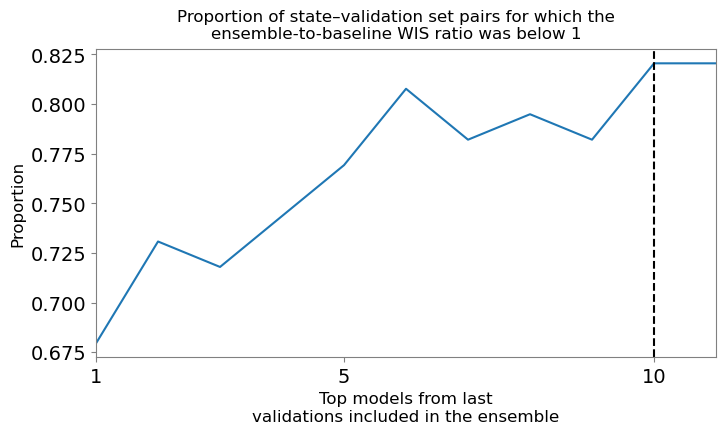

In [16]:
_, ax  = plt.subplots(figsize = (8,4))

df_ = (df_wis1.groupby('K')[['ensemble_better']].sum()/78).reset_index()

ax.plot(df_.K, df_.ensemble_better)

ax.set_xlabel('Top models from last\nvalidations included in the ensemble', fontsize = 12)

ax.set_ylabel('Proportion', fontsize = 12)

ax.set_xticks([1, 5, 10, 15, 20])

ax.set_xlim([1, df_preds.model.unique().shape[0]])

ax.axvline(10, linestyle = '--', color = 'black')

plt.suptitle('Proportion of state–validation set pairs for which the\n'
    'ensemble-to-baseline WIS ratio was below 1', fontsize = 12)

plt.savefig(f'../figures/wis_ratio_top_k_agg_{challenge}.png', dpi = 300, bbox_inches = 'tight')
plt.show()

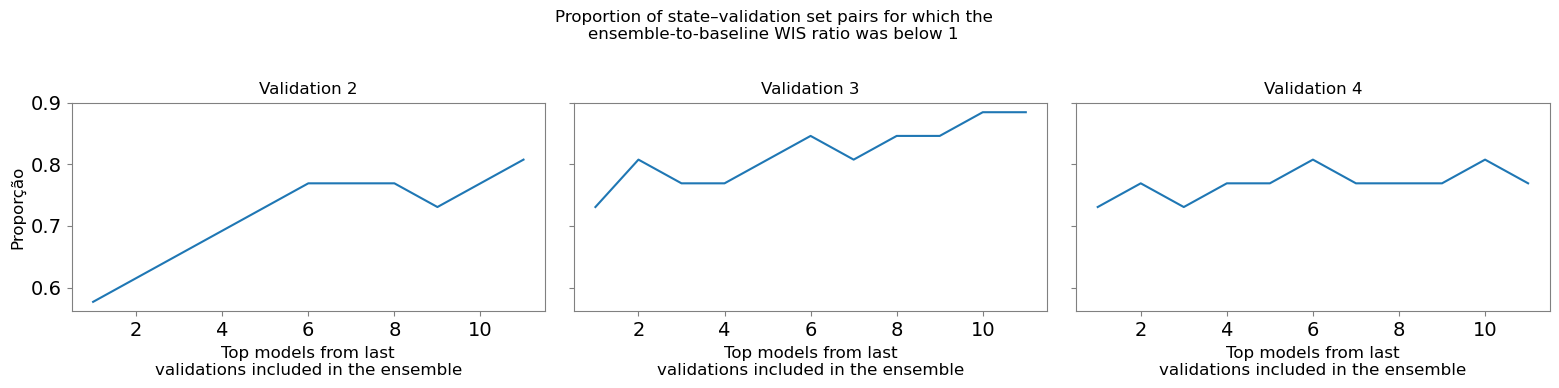

In [15]:
_, ax  = plt.subplots(1,3, figsize = (16,4), sharey = True)

for ax_, val in zip(ax.ravel(), [2,3,4]): 

    df_ = (df_wis1.loc[df_wis1.validation == val].groupby('K')[['ensemble_better']].sum()/26).reset_index()

    ax_.plot(df_.K, df_.ensemble_better)

    ax_.set_xlabel('Top models from last\nvalidations included in the ensemble', fontsize = 12)

    ax_.set_title(f'Validation {val}', fontsize = 12)


ax[0].set_ylabel('Proporção', fontsize = 12)

plt.suptitle('Proportion of state–validation set pairs for which the\n'
    'ensemble-to-baseline WIS ratio was below 1', fontsize = 12)

plt.tight_layout()

#plt.savefig('../figures/wis_ratio_top_k_agg.png', dpi = 300, bbox_inches = 'tight')

plt.show()